# Clasificador paisajes
Para este ejercicio vas a crear un clasificador automático de paisajes. Los datos los encontrarás como `seg_train.zip` y `seg_test.zip`. Se pide:
1. Cargar las imágenes. Mira cómo están almacenados los datos. Tendrás que recorrer las carpetas, cargar las imágenes en memoria y etiquetarlas con los nombres de las carpetas. Realiza un reshape de cada imagen (comienza el ejercicio con 32x32, para ir más rápido en las ejecuciones).
2. Investiga las imágenes, comprueba con algunas muestras que has cargado bien los datos.
3. Normaliza
4. Diseña la arquitectura de la red. Recuerda que es un algiritmo de clasificación. Ojo con las dimensiones de la entrada
5. Reserva un 20% de los datos del entrenamiento para validar.
6. Representa el objeto history
7. Evalua el modelo con los datos de test
8. Representa algunos de los paisajes donde el modelo comete errores
9. Crea una matriz de confusión con los errores del modelo

**NOTA apartado 1**: para el apartado 1 tendras que recorre las carpetas/imagenes con `os.listdir()`, e ir cargando todas las imagenes como arrays de numpy

**NOTA apartado 4**: empieza con un par de capas Conv2D + MaxPooling2D con activación relu y después la fully connected layer. on softmax como ultima capa

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/data_paisajes/

PROF_seg_test.zip  PROF_seg_train.zip


In [3]:
import zipfile
import os

ruta_zip = "/content/drive/MyDrive/data_paisajes/PROF_seg_train.zip"          # Ruta del ZIP
#destino = "carpeta_destino" # Carpeta donde se extraerá

# Crear carpeta destino si no existe
# os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
    zip_ref.extractall()

print("Descompresión de train completada.")

Descompresión de train completada.


In [4]:
import zipfile
import os

ruta_zip = "/content/drive/MyDrive/data_paisajes/PROF_seg_test.zip"          # Ruta del ZIP
#destino = "carpeta_destino" # Carpeta donde se extraerá

# Crear carpeta destino si no existe
# os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(ruta_zip, 'r') as zip_ref:
    zip_ref.extractall()

print("Descompresión de train completada.")

Descompresión de train completada.


In [5]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf

In [6]:
class_names = ['mountain','street','glacier', 'buildings','sea','forest']

IMAGE_SIZE = (100,100)

In [7]:
class_names_label = {class_name:i for i ,class_name in enumerate(class_names)}
class_names_label

{'mountain': 0,
 'street': 1,
 'glacier': 2,
 'buildings': 3,
 'sea': 4,
 'forest': 5}

In [8]:
from pathlib import Path

ROOT_PATH = os.getcwd()
TRAIN_PATH = Path(ROOT_PATH) / "seg_train"
TEST_PATH = Path(ROOT_PATH) / "seg_test"

In [9]:
# Como no son muchas imágenes ni tienen mucha definición, las voy a cargar en memoria
# ¡¡ojo!! Es para mostraros que también se puede hacer así
# pero SOLO si no ocupa demasiado en memoria. Siempre es más eficiente tener las imágenes en Google Drive
# y leerlas de ahí, si fueran tantas y con tanta definición como los perros y los gatos NO podría cargar todas en memoria
# (tendría que hacerlo como en los perros y los gatos)

def read_data(path, im_size, class_names_label):
    X = []
    y = []

    for folder in os.listdir(path):
        label = class_names_label[folder]
        folder_path = os.path.join(path,folder)
        # Iterar sobre todo lo que haya en path
        for file in os.listdir(folder_path):
            image_path = os.path.join(folder_path,file)
            image = cv2.imread(image_path)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, im_size)
            X.append(image)
            y.append(label)


    return np.array(X), np.array(y)


X_train, y_train = read_data(TRAIN_PATH, IMAGE_SIZE, class_names_label)
X_test, y_test = read_data(TEST_PATH, IMAGE_SIZE, class_names_label)

print(X_train.shape)
print(X_test.shape)

(14034, 100, 100, 3)
(3000, 100, 100, 3)


In [10]:
print(y_train.shape)
print(y_test.shape)

(14034,)
(3000,)


In [11]:
y_train

array([2, 2, 2, ..., 0, 0, 0], shape=(14034,))

In [12]:
from sklearn.utils import shuffle

X_train, y_train = shuffle(X_train, y_train, random_state=42)

In [13]:
y_train[0:10]

array([2, 0, 0, 5, 3, 4, 3, 3, 2, 0])

In [14]:
pd.DataFrame(y_train).value_counts()

,count
0,
0,2512
2,2404
1,2382
4,2274
5,2271
3,2191


In [15]:
X_train.max()

np.uint8(255)

forest


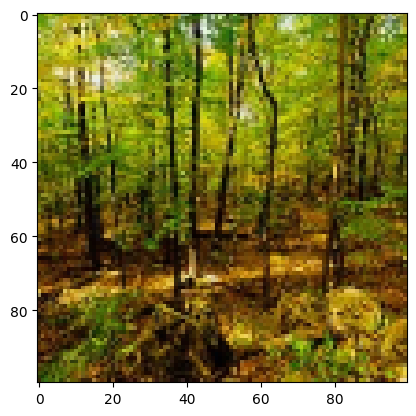

In [16]:
index = np.random.randint(X_train.shape[0])
print(class_names[y_train[index]])
plt.imshow(X_train[index]);

In [17]:
X_train_scal = X_train/255.0
X_test_scal = X_test/255.0

In [18]:
IMAGE_SIZE

(100, 100)

In [19]:
X_train_scal.shape

(14034, 100, 100, 3)

In [21]:
# Primera capa conv
# 3 porque tenemos 3 capas RGB
# 32 porque hemos elegido en esta capa de convolución hacer 32 filtros
# 3*3 porque en cada filtro tenemos una matriz de 3*3 pixeles
# 32 bias
3*32*3*3 + 32

896

In [22]:
# Segunda capa conv
# 32 porque tenemos 32 filtros en el output de la anterior capa
# 64 porque hemos elegido en esta capa de convolución hacer 64 filtros
# 3*3 porque en cada filtro tenemos una matriz de 3*3 pixeles
# 64 bias
32*64*3*3 + 64

18496

In [23]:
2304*128 + 128

295040

In [24]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 98, 98, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 49, 49, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 47, 47, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 33856)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    17,334,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,357,254 (66.21 MB)

 Trainable params: 17,357,254 (66.21 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
model.compile(optimizer= 'adam', loss= "sparse_categorical_crossentropy", metrics=['accuracy'])

In [26]:
# entreno 30 épocas para conseguir un score cercano a 0.8
# batch 256 limitación de memoria

In [27]:
history = model.fit(X_train_scal, y_train, batch_size=256, epochs=30, validation_split=0.1)

Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 438ms/step - accuracy: 0.4469 - loss: 1.9034 - val_accuracy: 0.5883 - val_loss: 1.0522
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.6697 - loss: 0.8796 - val_accuracy: 0.6738 - val_loss: 0.8626
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.7425 - loss: 0.7122 - val_accuracy: 0.6937 - val_loss: 0.8024
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.7787 - loss: 0.6205 - val_accuracy: 0.7486 - val_loss: 0.7008
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.8209 - loss: 0.5150 - val_accuracy: 0.7187 - val_loss: 0.7695
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 83ms/step - accuracy: 0.8568 - loss: 0.4154 - val_accuracy: 0.7415 - val_loss: 0.7364
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 89ms/step - accuracy: 0.8886 - loss: 0.3333 - val_accuracy: 0.7593 - val_loss: 0.6984
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 80ms/step - accuracy: 0.9134 - loss: 0.2699 - val_accuracy: 0.7614 -

In [28]:
df_hist = pd.DataFrame(history.history)
df_hist

,accuracy,loss,val_accuracy,val_loss
0,0.446873,1.903409,0.588319,1.052162
1,0.669675,0.879554,0.673789,0.862645
2,0.742518,0.712185,0.693732,0.802366
3,0.778701,0.620476,0.748576,0.700769
4,0.820903,0.515001,0.718661,0.769450
5,0.856770,0.415442,0.741453,0.736388
6,0.888599,0.333342,0.759259,0.698426
7,0.913381,0.269903,0.761396,0.796032
8,0.938717,0.197571,0.742877,0.830571
9,0.956057,0.146813,0.765670,0.875321


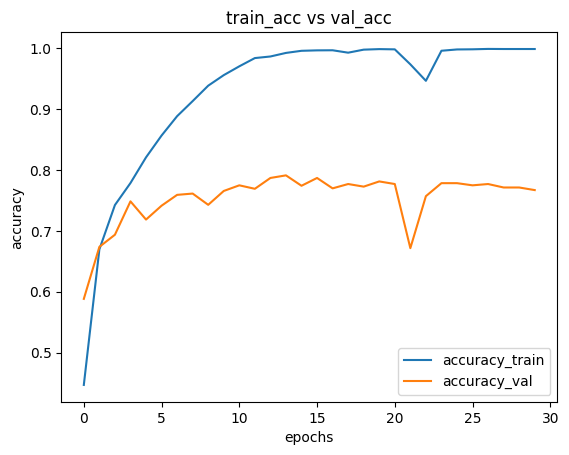

In [29]:
plt.figure()
plt.plot(df_hist['accuracy'], label="accuracy_train")
plt.plot(df_hist['val_accuracy'], label="accuracy_val")
plt.title("train_acc vs val_acc")
plt.ylabel("accuracy")
plt.xlabel("epochs")
plt.legend()

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.7670 - loss: 1.3217


94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


array([[0.  , 0.  , 1.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  ],
       [0.  , 0.  , 1.  , 0.  , 0.  , 0.  ],
       ...,
       [0.93, 0.  , 0.05, 0.  , 0.01, 0.  ],
       [0.03, 0.  , 0.41, 0.53, 0.03, 0.  ],
       [1.  , 0.  , 0.  , 0.  , 0.  , 0.  ]],
      shape=(3000, 6), dtype=float32)

In [32]:
pred_labels = np.argmax(predictions, axis=1)

In [33]:
pred_labels

array([2, 2, 2, ..., 0, 3, 0], shape=(3000,))

glacier


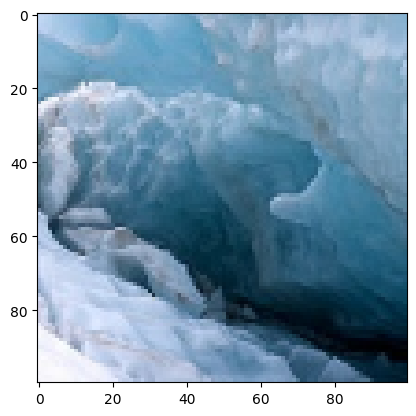

In [34]:
index=3
print(class_names[y_test[index]])
plt.imshow(X_test[index]);

In [35]:
class_names[pred_labels[index]]

'glacier'

In [36]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [37]:
class_names_label

{'mountain': 0,
 'street': 1,
 'glacier': 2,
 'buildings': 3,
 'sea': 4,
 'forest': 5}

<Axes: >

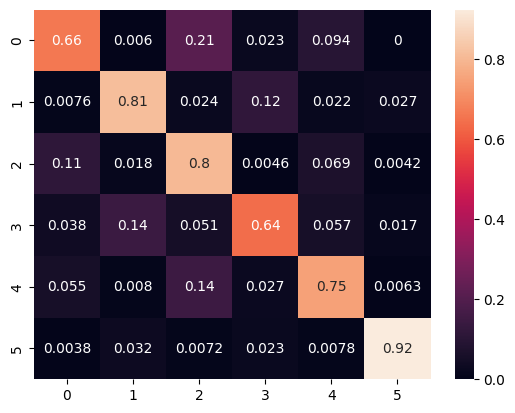

Guardamos el modelo

In [42]:
import os

SAVE_PATH = '/content/drive/MyDrive/Paisajes'

os.makedirs(SAVE_PATH, exist_ok=True)

In [43]:
model.save(f'{SAVE_PATH}/modelo_paisajes.keras')

In [44]:
os.listdir(SAVE_PATH)

['modelo_paisajes.keras']